<a href="https://colab.research.google.com/github/GGPwis/Procesamiento-del-Habla/blob/main/PDF_PORTAL_GUSSTAVO_GABRIEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico: Extracción y Análisis de Datos desde PDF
**Alumno:** Gustavo Gabriel Portal

## 1. Adquisición del documento y extracción de metadatos

Para este trabajo práctico se seleccionó el **Reporte de Impacto 2025 de Mercado Libre**, un documento en formato PDF que presenta información sobre las actividades de la empresa, sus resultados y el uso de nuevas tecnologías, incluida la inteligencia artificial.

El objetivo de esta primera etapa es descargar el documento desde una URL pública, abrirlo mediante Python y consultar sus metadatos.

### Librerías utilizadas

- **Requests:** para descargar el archivo PDF desde internet.
- **PyMuPDF:** para abrir el documento, consultar sus metadatos y extraer su contenido textual.
- **pdfplumber:** para identificar y extraer las tablas presentes en el documento.
- **Pandas:** para organizar y limpiar los datos extraídos mediante DataFrames.
- **NLTK:** para procesar el texto, realizar la tokenización y eliminar (*stopwords*).
- **Matplotlib:** para representar gráficamente las palabras más frecuentes.

**Fuente:** https://cdn.sustentabilidadmercadolibre.com/MELI_Reporte_Anual_2025_v11_25fa2f6699.pdf

In [66]:
!pip install pdfplumber pymupdf pandas requests -q

In [67]:
# Descarga de archivos desde internet
import requests

# Lectura, exploración y extracción de contenido PDF
import pymupdf
import pdfplumber

# Organización y tratamiento de datos
import pandas as pd

# Procesamiento del lenguaje natural
import nltk

# Visualización de datos
import matplotlib
import matplotlib.pyplot as plt

# Verificación de las versiones de las librerías
print("--- VERSIONES DE LAS LIBRERÍAS ---")
print("Requests:", requests.__version__)
print("PyMuPDF:", pymupdf.VersionBind)
print("pdfplumber:", pdfplumber.__version__)
print("Pandas:", pd.__version__)
print("NLTK:", nltk.__version__)
print("Matplotlib:", matplotlib.__version__)

--- VERSIONES DE LAS LIBRERÍAS ---
Requests: 2.32.4
PyMuPDF: 1.28.2
pdfplumber: 0.11.10
Pandas: 2.2.3
NLTK: 3.9.1
Matplotlib: 3.10.0


In [68]:
# 1. Definir la URL y el nombre del archivo
url = "https://cdn.sustentabilidadmercadolibre.com/MELI_Reporte_Anual_2025_v11_25fa2f6699.pdf"
nombre_archivo = "reporte_mercadolibre_2025.pdf"

# 2. Descargar el PDF desde la URL pública
respuesta = requests.get(url)
respuesta.raise_for_status()

# 3. Guardar el archivo descargado
with open(nombre_archivo, "wb") as archivo:
    archivo.write(respuesta.content)

print("¡Descarga completada correctamente!\n")

# 4. Abrir el PDF utilizando ambas librerías
documento = pymupdf.open(nombre_archivo)
documento_plumber = pdfplumber.open(nombre_archivo)

# 5. Obtener los metadatos del documento
metadatos = documento.metadata

# 6. Mostrar los metadatos solicitados
print("--- METADATOS DEL DOCUMENTO ---")
print(f"Título: {metadatos.get('title') or 'No especificado'}")
print(f"Autor(es): {metadatos.get('author') or 'No especificado'}")
print(f"Software de creación: {metadatos.get('creator') or 'No especificado'}")
print(f"Número total de páginas: {documento.page_count}")

¡Descarga completada correctamente!

--- METADATOS DEL DOCUMENTO ---
Título: Reporte de Impacto 2025
Autor(es): Mercado Libre
Software de creación: Adobe InDesign 21.0 (Windows)
Número total de páginas: 115


### Observaciones sobre los metadatos

El PDF se descargó correctamente mediante `requests`. Con `PyMuPDF` se obtuvieron los siguientes datos:

- **Título:** Reporte de Impacto 2025.
- **Autor:** Mercado Libre.
- **Software de creación:** Adobe InDesign 21.0 (Windows).
- **Páginas:** 115.

Se comprobó que el documento puede abrirse y que sus metadatos son accesibles mediante Python.

## 2. Análisis estructural del texto

Se utilizará **PyMuPDF** para extraer el texto del documento mediante `get_text()` y analizar su estructura original.

Se examinarán los saltos de línea, los espacios y otros caracteres especiales que permiten identificar párrafos, secciones y bloques de texto.

In [69]:
# Extraer el texto completo con PyMuPDF
texto_completo_mupdf = ""

for pagina in documento:
    texto_pagina = pagina.get_text("text")
    if texto_pagina:
        texto_completo_mupdf += texto_pagina + "\n"

print("Caracteres extraídos:", len(texto_completo_mupdf))
print("Palabras aproximadas:", len(texto_completo_mupdf.split()))

Caracteres extraídos: 244554
Palabras aproximadas: 36384


In [70]:
# Visualizar los primeros caracteres del texto extraído
print(texto_completo_mupdf[:500])

# Inspeccionar los caracteres especiales
print(repr(texto_completo_mupdf[:500]))

Reporte
de Impacto
2025

Contenidos
Experiencia 
de usuario
Negocio
Sobre este 
reporte
Cultura y 
equipo
Impacto social
Ambiente 
Indicadores 
complementarios
Reporte de 
Impacto 2025
Sobre este reporte
Negocio
Experiencia de usuario
Cultura y equipo
Impacto social
Ambiente 
Indicadores
2

Sobre este 
reporte
	» Creación de valor	
07
	» Materialidad	
06
	» Parámetros del reporte	
05
	» Mensaje del CEO	
04
Reporte de 
Impacto 2025
Negocio
Experiencia de usuario
Cultura y equipo
Impacto social
Am
'Reporte\nde Impacto\n2025\n\nContenidos\nExperiencia \nde usuario\nNegocio\nSobre este \nreporte\nCultura y \nequipo\nImpacto social\nAmbiente \nIndicadores \ncomplementarios\nReporte de \nImpacto 2025\nSobre este reporte\nNegocio\nExperiencia de usuario\nCultura y equipo\nImpacto social\nAmbiente \nIndicadores\n2\n\nSobre este \nreporte\n\t» Creación de valor\t\n07\n\t» Materialidad\t\n06\n\t» Parámetros del reporte\t\n05\n\t» Mensaje del CEO\t\n04\nReporte de \nImpacto 2025\nNegocio\nExperie

In [71]:
# Extraer el texto completo con pdfplumber
texto_completo_plumber = ""

for pagina in documento_plumber.pages:
    texto_pagina = pagina.extract_text()
    if texto_pagina:
        texto_completo_plumber += texto_pagina + "\n"

print("Caracteres extraídos:", len(texto_completo_plumber))
print("Palabras aproximadas:", len(texto_completo_plumber.split()))

Caracteres extraídos: 240301
Palabras aproximadas: 36302


In [72]:
# Visualizar los primeros caracteres del texto extraído
print(texto_completo_plumber[:500])

# Inspeccionar los caracteres especiales
print(repr(texto_completo_plumber[:500]))

Reporte
de Impacto
2025
Contenidos
Sobre este Experiencia
Negocio
reporte de usuario
Cultura y
Impacto social Ambiente
equipo
Indicadores
complementarios
Reporte de
Sobre este reporte Negocio Experiencia de usuario Cultura y equipo Impacto social Ambiente Indicadores 2
Impacto 2025
Sobre este
» Mensaje del CEO 04
» Parámetros del reporte 05
reporte
» Materialidad 06
» Creación de valor 07
Reporte de
Sobre este reporte Negocio Experiencia de usuario Cultura y equipo Impacto social Ambiente Indica
'Reporte\nde Impacto\n2025\nContenidos\nSobre este Experiencia\nNegocio\nreporte de usuario\nCultura y\nImpacto social Ambiente\nequipo\nIndicadores\ncomplementarios\nReporte de\nSobre este reporte Negocio Experiencia de usuario Cultura y equipo Impacto social Ambiente Indicadores 2\nImpacto 2025\nSobre este\n» Mensaje del CEO 04\n» Parámetros del reporte 05\nreporte\n» Materialidad 06\n» Creación de valor 07\nReporte de\nSobre este reporte Negocio Experiencia de usuario Cultura y equipo Impact

In [73]:
# Comparar los caracteres separadores de ambas extracciones
for nombre, texto in [("PyMuPDF", texto_completo_mupdf),
                      ("pdfplumber", texto_completo_plumber)]:
    print(f"\n--- {nombre} ---")
    print("Saltos de línea:", texto.count("\n"))
    print("Tabulaciones:", texto.count("\t"))
    print("Retornos de carro:", texto.count("\r"))


--- PyMuPDF ---
Saltos de línea: 7937
Tabulaciones: 298
Retornos de carro: 0

--- pdfplumber ---
Saltos de línea: 4292
Tabulaciones: 0
Retornos de carro: 0


### Observaciones del análisis estructural

Se extrajo el texto completo del PDF utilizando PyMuPDF y pdfplumber.

**PyMuPDF** recuperó 244.554 caracteres y 36.384 palabras aproximadas, mientras que **pdfplumber** obtuvo 240.301 caracteres y 36.302 palabras.

En cuanto a los separadores, PyMuPDF presentó 7.937 saltos de línea (`\n`) y 298 tabulaciones (`\t`); pdfplumber registró 4.292 saltos de línea y ninguna tabulación. No se encontraron retornos de carro (`\r`).

Se observó que ambas librerías interpretan de manera diferente la disposición de títulos, párrafos y columnas, por lo que el texto extraído no siempre conserva el orden visual del PDF.

## 3. Extracción de datos tabulares

Se utilizará `pdfplumber` para identificar y extraer una tabla del reporte de Mercado Libre. Luego, mediante `pandas`, se convertirá en un DataFrame para organizar los datos, nombrar las columnas y eliminar posibles filas vacías.

In [74]:
# Seleccionar la página 98 del PDF
pagina = documento_plumber.pages[97]

# Buscar las tablas de esa página
tablas = pagina.find_tables()

# Mostrar la cantidad de tablas encontradas
print("Tablas encontradas:", len(tablas))

Tablas encontradas: 3


In [75]:
# Mostrar el contenido de las 3 tablas
for i, tabla in enumerate(tablas):
    print(f"\n--- TABLA {i + 1} ---")
    for fila in tabla.extract():
        print(fila)


--- TABLA 1 ---
['Diversidad de empleados\nGRI 405-1 SASB CG-EC-330a.3\nTotal de empleados por categoría profesional y género Total de empleados por categoría profesional y grupo de edad\n2024 2025 2024 2025\nMujeres Hombres Mujeres Hombres Entre Entre\nHasta Más de Hasta Más de\n31 y 50 31 y 50\nReps + Team Leaders 26.940 23.330 43.333 37.612 30 años 51 años 30 años 51 años\naños años\nAnalistas y asistentes 8.052 15.698 10.070 20.598\nReps + Team\n31.470 18.262 1.545 48.970 28.026 3.949\nSupervisores 2.175 4.326 2.617 5.083 Leaders\nGerentes/Executives Assistant 873 1.534 1.025 1.818 Analistas y\n9.669 12.930 144 11.632 18.679 357\nasistentes\nGerentes Senior 271 592 328 695\nSupervisores 585 5.837 79 639 6.922 139\nDirector 81 278 98 330\nGerentes/\nVP/CEO 6 51 7 56\nExecutives 49 2.314 44 48 2.715 80\nTotal 38.398 45.809 57.478 66.192\nAssistant\nGerentes Senior 2 837 24 1 978 44\nDirector 0 342 17 0 388 40\nVP/CEO 0 46 11 0 44 19\nTotal 41.775 40.568 1.864 61.290 57.752 4.628']
[

In [76]:
# Seleccionar la tercera tabla de la página 98
datos_tabla = tablas[2].extract()

# Convertir la tabla en un DataFrame
df = pd.DataFrame(datos_tabla)

# Mostrar los datos originales
display(df)

,0,1,2,3,4,5,6
0,,2024,None,None,2025,None,None
1,,Hasta\n30 años,Entre\n31 y 50\naños,Más de\n51 años,Hasta\n30 años,Entre\n31 y 50\naños,Más de\n51 años
2,Reps + Team\nLeaders,31.470,18.262,1.545,48.970,28.026,3.949
3,Analistas y\nasistentes,9.669,12.930,144,11.632,18.679,357
4,Supervisores,585,5.837,79,639,6.922,139
5,Gerentes/\nExecutives\nAssistant,49,2.314,44,48,2.715,80
6,Gerentes Senior,2,837,24,1,978,44
7,Director,0,342,17,0,388,40
8,VP/CEO,0,46,11,0,44,19
9,Total,41.775,40.568,1.864,61.290,57.752,4.628


In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       10 non-null     object
 1   1       10 non-null     object
 2   2       9 non-null      object
 3   3       9 non-null      object
 4   4       10 non-null     object
 5   5       9 non-null      object
 6   6       9 non-null      object
dtypes: object(7)
memory usage: 692.0+ bytes


In [78]:
df.describe()

,0,1,2,3,4,5,6
count,10,10,9,9,10,9,9
unique,9,9,9,9,9,9,9
top,,0,Entre\n31 y 50\naños,Más de\n51 años,0,Entre\n31 y 50\naños,Más de\n51 años
freq,2,2,1,1,2,1,1


In [79]:
# 1. Asignar nombres a las columnas
df.columns = [
    "Categoría",
    "2024_Hasta30", "2024_31a50", "2024_Mas51",
    "2025_Hasta30", "2025_31a50", "2025_Mas51"
]

# 2. Eliminar las dos filas de encabezados originales
df = df.iloc[2:].reset_index(drop=True)

# 3. Eliminar los saltos de línea de las categorías
df["Categoría"] = df["Categoría"].str.replace("\n", " ", regex=False)

# 4. Eliminar los puntos de miles y convertir a enteros
columnas_numericas = df.columns[1:]

for columna in columnas_numericas:
    df[columna] = df[columna].str.replace(".", "", regex=False).astype(int)

# 5. Eliminar posibles filas completamente vacías
df = df.dropna(how="all")

# 6. Mostrar el DataFrame limpio
display(df)

,Categoría,2024_Hasta30,2024_31a50,2024_Mas51,2025_Hasta30,2025_31a50,2025_Mas51
0,Reps + Team Leaders,31470,18262,1545,48970,28026,3949
1,Analistas y asistentes,9669,12930,144,11632,18679,357
2,Supervisores,585,5837,79,639,6922,139
3,Gerentes/ Executives Assistant,49,2314,44,48,2715,80
4,Gerentes Senior,2,837,24,1,978,44
5,Director,0,342,17,0,388,40
6,VP/CEO,0,46,11,0,44,19
7,Total,41775,40568,1864,61290,57752,4628


In [80]:
# Verificar los tipos de datos
print("--- TIPOS DE DATOS ---")
print(df.dtypes)

# Comprobar si existen valores nulos
print("\n--- VALORES NULOS ---")
print(df.isnull().sum())

--- TIPOS DE DATOS ---
Categoría       object
2024_Hasta30     int64
2024_31a50       int64
2024_Mas51       int64
2025_Hasta30     int64
2025_31a50       int64
2025_Mas51       int64
dtype: object

--- VALORES NULOS ---
Categoría       0
2024_Hasta30    0
2024_31a50      0
2024_Mas51      0
2025_Hasta30    0
2025_31a50      0
2025_Mas51      0
dtype: int64


### Observaciones de la extracción tabular

Se extrajo de la página 98 la tabla de empleados por categoría profesional y grupo de edad, utilizando `pdfplumber` y `pandas`.

Se organizaron los encabezados, eliminaron los saltos de línea en las categorías y convirtieron los valores numéricos a enteros.

El DataFrame final contiene **8 filas y 7 columnas**, sin valores nulos. Se conservó la fila de totales para respetar la información original.

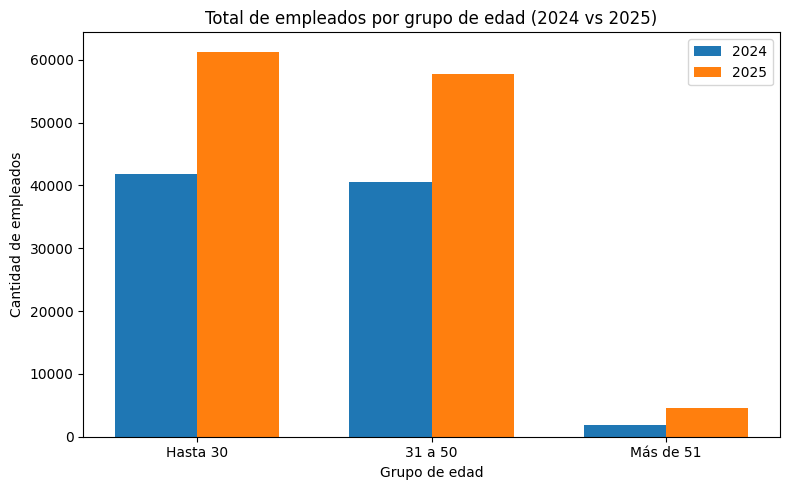

In [81]:
import numpy as np
# Tomar la fila de totales
fila_total = df[df["Categoría"] == "Total"].iloc[0]

# Etiquetas y valores
grupos_edad = ["Hasta 30", "31 a 50", "Más de 51"]
valores_2024 = [fila_total["2024_Hasta30"], fila_total["2024_31a50"], fila_total["2024_Mas51"]]
valores_2025 = [fila_total["2025_Hasta30"], fila_total["2025_31a50"], fila_total["2025_Mas51"]]

# Posiciones para las barras
x = np.arange(len(grupos_edad))
ancho = 0.35

# Crear gráfico
plt.figure(figsize=(8, 5))
plt.bar(x - ancho/2, valores_2024, width=ancho, label="2024")
plt.bar(x + ancho/2, valores_2025, width=ancho, label="2025")

# Personalización
plt.xticks(x, grupos_edad)
plt.ylabel("Cantidad de empleados")
plt.xlabel("Grupo de edad")
plt.title("Total de empleados por grupo de edad (2024 vs 2025)")
plt.legend()
plt.tight_layout()
plt.show()

A modo de exploración adicional, se representaron gráficamente los totales de empleados por grupo de edad para 2024 y 2025. El gráfico permite observar con mayor claridad el crecimiento de la cantidad de empleados en todos los grupos etarios, especialmente en los rangos de hasta 30 años y entre 31 y 50 años.

## 4. Análisis de frecuencias (NLP básico)

Se seleccionará una página con texto narrativo para realizar un análisis de frecuencias utilizando `NLTK`.

Se aplicará tokenización, conversión a minúsculas y eliminación de signos de puntuación y *stopwords*. Finalmente, se utilizará `Matplotlib` para representar las 15 palabras más frecuentes.

In [82]:
# Seleccionar la página 28 del PDF
pagina_nlp = documento[27]

# Extraer el texto
texto_nlp = pagina_nlp.get_text("text")

# Mostrar el contenido extraído
print(texto_nlp)

IA para mejorar la experiencia
Utilizamos la IA para aumentar nuestra productividad 
y acelerar el impacto en los negocios.
Miramos a la tecnología con el objetivo de incorporar cada vez 
más recursos pensando en el impacto que podemos generar en 
el negocio, la eficiencia productiva y en la experiencia del usuario. 
Desde los comienzos, la inteligencia artificial (IA) ha sido una aliada 
clave en diversos procesos estratégicos de nuestro negocio. 
En el marketplace y en el ecosistema fintech, aplicamos modelos de 
reconocimiento de imágenes, procesamiento de lenguaje natural 
y algoritmos predictivos para prevenir y detectar fraudes, analizar 
patrones de comportamiento y proteger a usuarios y vendedores. 
También empleamos IA en el análisis de la documentación 
proporcionada por los vendedores, con el objetivo de prevenir el 
lavado de dinero y garantizar el uso ético de nuestra plataforma.
En los servicios financieros, utilizamos redes neuronales que 
analizan transacciones en tiemp

In [83]:
# Seleccionar la página 28
pagina_nlp = documento[27]

# Definir una región que excluya el pie de página
rectangulo = pagina_nlp.rect
zona_texto = pymupdf.Rect(
    0, 0,
    rectangulo.width,
    rectangulo.height * 0.92
)

# Extraer el texto de esa región
texto_nlp = pagina_nlp.get_text("text", clip=zona_texto)

print(texto_nlp)

IA para mejorar la experiencia
Utilizamos la IA para aumentar nuestra productividad 
y acelerar el impacto en los negocios.
Miramos a la tecnología con el objetivo de incorporar cada vez 
más recursos pensando en el impacto que podemos generar en 
el negocio, la eficiencia productiva y en la experiencia del usuario. 
Desde los comienzos, la inteligencia artificial (IA) ha sido una aliada 
clave en diversos procesos estratégicos de nuestro negocio. 
En el marketplace y en el ecosistema fintech, aplicamos modelos de 
reconocimiento de imágenes, procesamiento de lenguaje natural 
y algoritmos predictivos para prevenir y detectar fraudes, analizar 
patrones de comportamiento y proteger a usuarios y vendedores. 
También empleamos IA en el análisis de la documentación 
proporcionada por los vendedores, con el objetivo de prevenir el 
lavado de dinero y garantizar el uso ético de nuestra plataforma.
En los servicios financieros, utilizamos redes neuronales que 
analizan transacciones en tiemp

In [84]:
import nltk
from nltk.tokenize import word_tokenize

# Descargar los recursos necesarios
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [85]:
# Convertir el texto a minúsculas
texto_minusculas = texto_nlp.lower()

# Tokenizar el texto
tokens = word_tokenize(texto_minusculas, language="spanish")

# Mostrar los primeros 30 tokens
print("Primeros Tokens:\n", tokens[:30])
print("Cantidad total de tokens:", len(tokens))

Primeros Tokens:
 ['ia', 'para', 'mejorar', 'la', 'experiencia', 'utilizamos', 'la', 'ia', 'para', 'aumentar', 'nuestra', 'productividad', 'y', 'acelerar', 'el', 'impacto', 'en', 'los', 'negocios', '.', 'miramos', 'a', 'la', 'tecnología', 'con', 'el', 'objetivo', 'de', 'incorporar', 'cada']
Cantidad total de tokens: 713


In [86]:
from nltk.corpus import stopwords

# Descargar las stopwords
nltk.download("stopwords")

# Obtener las stopwords en español
palabras_vacias = set(stopwords.words("spanish"))

# Conservar solamente palabras alfabéticas que no sean stopwords
tokens_limpios = []

for palabra in tokens:
    if palabra.isalpha() and palabra not in palabras_vacias:
        tokens_limpios.append(palabra)

# Mostrar el resultado
print(tokens_limpios[:30])
print("Tokens originales:", len(tokens))
print("Tokens limpios:", len(tokens_limpios))

['ia', 'mejorar', 'experiencia', 'utilizamos', 'ia', 'aumentar', 'productividad', 'acelerar', 'impacto', 'negocios', 'miramos', 'tecnología', 'objetivo', 'incorporar', 'cada', 'vez', 'recursos', 'pensando', 'impacto', 'podemos', 'generar', 'negocio', 'eficiencia', 'productiva', 'experiencia', 'usuario', 'comienzos', 'inteligencia', 'artificial', 'ia']
Tokens originales: 713
Tokens limpios: 351


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [89]:
from nltk.probability import FreqDist

# Calcular la frecuencia de las palabras
frecuencias = FreqDist(tokens_limpios)

# Obtener las 15 palabras más frecuentes
top_15 = frecuencias.most_common(20)

# Mostrar los resultados
for palabra, cantidad in top_15:
    print(f"{palabra}-> {cantidad}")

ia-> 11
tecnología-> 4
inteligencia-> 4
artificial-> 4
asistente-> 4
experiencia-> 3
utilizamos-> 3
modelos-> 3
usuarios-> 3
uso-> 3
ético-> 3
riesgos-> 3
mercado-> 3
tecnologías-> 3
propiedad-> 3
intelectual-> 3
cláusulas-> 3
mejorar-> 2
aumentar-> 2
impacto-> 2


In [90]:
# Agregar palabras poco relevantes al análisis
palabras_vacias.update(["así"])

# Volver a filtrar los tokens
tokens_limpios = []

for palabra in tokens:
    if palabra.isalpha() and palabra not in palabras_vacias:
        tokens_limpios.append(palabra)

# Recalcular las frecuencias
frecuencias = FreqDist(tokens_limpios)
top_15 = frecuencias.most_common(15)

# Mostrar el resultado actualizado
for palabra, cantidad in top_15:
    print(f"{palabra}-> {cantidad}")

ia-> 11
tecnología-> 4
inteligencia-> 4
artificial-> 4
asistente-> 4
experiencia-> 3
utilizamos-> 3
modelos-> 3
usuarios-> 3
uso-> 3
ético-> 3
riesgos-> 3
mercado-> 3
tecnologías-> 3
propiedad-> 3


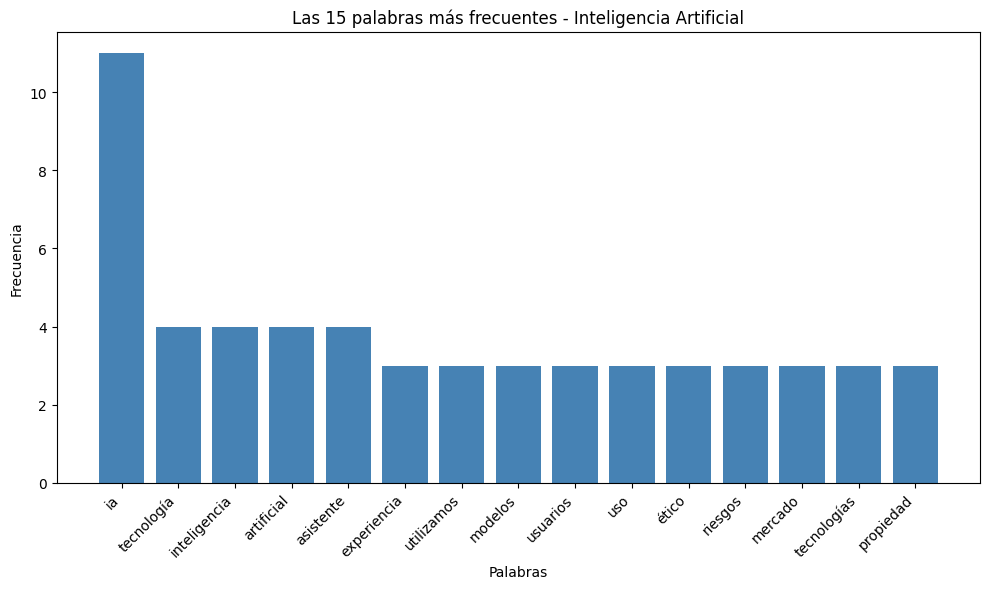

In [65]:
# Separar las palabras y sus frecuencias
palabras = [palabra for palabra, cantidad in top_15]
cantidades = [cantidad for palabra, cantidad in top_15]

# Crear el gráfico de barras
plt.figure(figsize=(10, 6))
plt.bar(palabras, cantidades, color="steelblue")

# Personalizar el gráfico
plt.title("Las 15 palabras más frecuentes - Inteligencia Artificial")
plt.xlabel("Palabras")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### Análisis de frecuencias

El análisis de la página 28 permitió identificar que la palabra más frecuente es **«ia»**, con 11 apariciones, seguida de «tecnología», «inteligencia», «artificial» y «asistente», con 4 apariciones cada una.

Durante la limpieza se eliminaron signos de puntuación, números y palabras vacías (*stopwords*). También se identificó la palabra «así» como poco relevante y se incorporó a la lista de exclusión.

Los resultados reflejan que el texto se centra en la aplicación de la inteligencia artificial y sus herramientas en diferentes procesos de la empresa.

## Conclusión general

En este trabajo práctico se desarrolló un proceso de extracción, limpieza y análisis de información a partir del *Reporte de Impacto 2025* de Mercado Libre, utilizando Python.

Se trabajó con las librerías `PyMuPDF` y `pdfplumber` para extraer texto y datos tabulares, identificando diferencias en la forma en que ambas herramientas recuperan la información. Posteriormente, mediante `pandas`, se organizaron y limpiaron los datos de una tabla para facilitar su análisis.

Finalmente, se aplicaron técnicas básicas de procesamiento del lenguaje natural con `NLTK`, como la tokenización, la eliminación de palabras vacías y el cálculo de frecuencias. Los resultados se representaron mediante un gráfico de barras y una nube de palabras.

Este trabajo permitió comprender la importancia de la limpieza y preparación de los datos, ya que la información extraída de un PDF no siempre está organizada para su análisis directo.

## Fuentes y uso de IA

**Fuente:** Mercado Libre. *Reporte de Impacto 2025*. [Documento PDF](https://cdn.sustentabilidadmercadolibre.com/MELI_Reporte_Anual_2025_v11_25fa2f6699.pdf).

**Herramientas:** Python, Google Colab y librerías utilizadas en el análisis.

**Uso de IA:** Se utilizó ChatGPT (OpenAI) como apoyo para comprender el código, resolver dudas, detectar errores y mejorar el desarrollo del trabajo. Los procedimientos y resultados fueron revisados y comprobados durante su ejecución.